Students are advised to review and adhere to the submission requirements documented after the assessment task. 

This is an individual Assessment using the PYTHON programming language. Develop and deploy unsupervised machine learning models in any one of the following areas only and analyse the results.
●	Transport
●	Housing and Zoning
●	Stock market dataset (only from last 10 years) from only website: https://finance.yahoo.com/quote/CSV/history/ 
The dataset should have a decent number of rows and columns, such as minimum 7 columns (for example, type of variables may be categorical, continuous, and discrete) after cleaning to justify the use of the machine learning modelling approach. The type of question(s) that you should formulate for the Assessment will depend on the chosen domain of the dataset as mentioned above. (Note: No marks will be awarded if the dataset is not based on the above-mentioned guidelines.)
Assessment questions could be: (this is a small, suggested, sample of questions, other questions may be more appropriate to your Assessment)

●	How to measure similarity or dissimilarity between different clusters?
●	Which clustering solution do you prefer, and why? 
●	How to analyse and investigate an inflation rate for a specific product from the provided time series dataset?  

You will present their findings and defend the results in the form of a poster presentation. Your poster should capture the following aspects that are relevant to your Assessment investigations. All practical implementations are carried in the Jupyter notebook (Note: The code in the form of Python files will not be accepted.)

i.	A precise introduction, motivation, description of problem domain, Assessment objectives and the rationale for the chosen dataset in the above-mentioned areas. 
(15 marks)
ii.	Which clustering algorithms would you consider for segmentation, and why? Implement the solutions and discuss the differences between silhouette score and Davies-Bouldin index in the context of clustering. Compare the results obtained from any two clustering algorithms from your own chosen dataset.
(30 marks)
iii.	Implement your solutions and discuss what insights can you derive from the initial exploration of the time series data based on the provided topics? Describe any trends, seasonality, or anomalies observed. How did you determine the appropriate parameters (p, d, q) for the ARIMA/ SARIMA model. Evaluate the performance of the ARIMA/ SARIMA model in forecasting future values, highlighting any strengths and limitations based on your chosen dataset.
(30 marks)
iv.	Interpret and justify the results based on the problem specification or Assessment objectives by using suitable visualizations. Comments and description of Python code, conclusions of the Assessment should be specified in the poster as well as in the Jupyter notebook. Citations and references should follow the Harvard style. You are required to record a video presentation to explain and justify your poster presentation and the code in the Jupyter Notebook. The video should not exceed 5 minutes in duration, and the use of AI-generated voices or agents is not permitted. The format of video recording is mentioned below


In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("hour.csv")

df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (17379, 17)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [8]:
print("Missing values by column:\n", df.isnull().sum())

print("\n Number of duplicated rows:", df.duplicated().sum())

Missing values by column:
 instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

 Number of duplicated rows: 0


In [9]:
data = df.copy()

In [11]:
data["dteday"] = pd.to_datetime(data["dteday"])

data = data.sort_values(["dteday", "hr"]).reset_index(drop=True)

In [14]:
print("Start date:", data["dteday"].min())
print("End date:", data["dteday"].max())
print("Rows after sorting:", data.shape[0])

Start date: 2011-01-01 00:00:00
End date: 2012-12-31 00:00:00
Rows after sorting: 17379


In [15]:
data.describe()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2012-01-02 04:08:34.552045568,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
min,1.0000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2011-07-04 00:00:00,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,2012-01-02 00:00:00,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,2012-07-02 00:00:00,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000
std,5017.0295,NaN,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599


<function matplotlib.pyplot.show(close=None, block=None)>

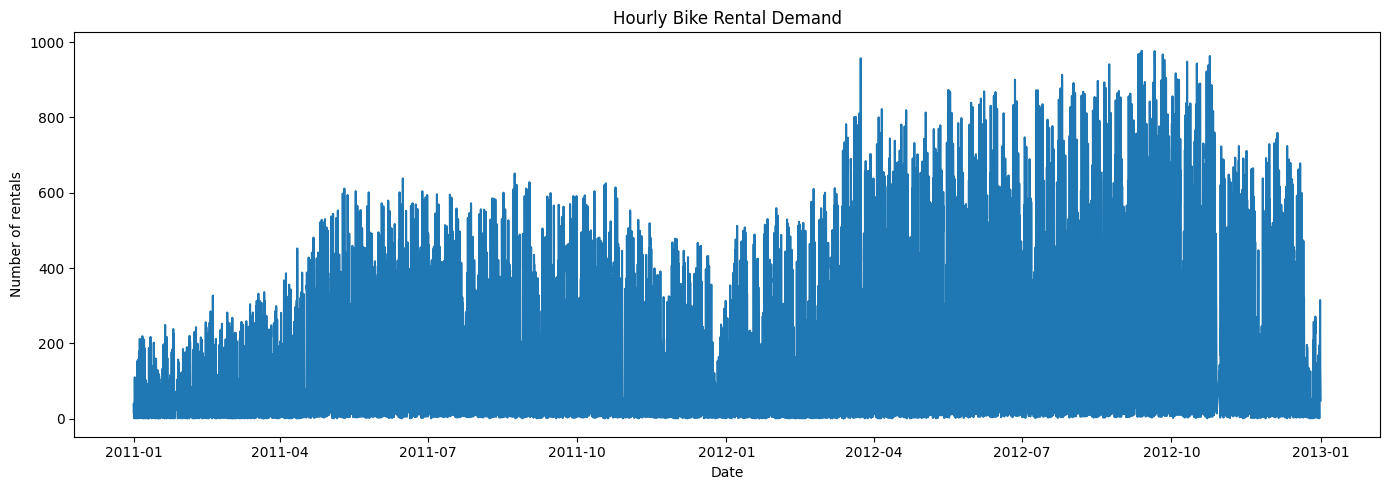

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(data["dteday"] + pd.to_timedelta(data["hr"], unit="h"), data["cnt"])
plt.title("Hourly Bike Rental Demand")
plt.xlabel("Date")
plt.ylabel("Number of rentals")
plt.tight_layout()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

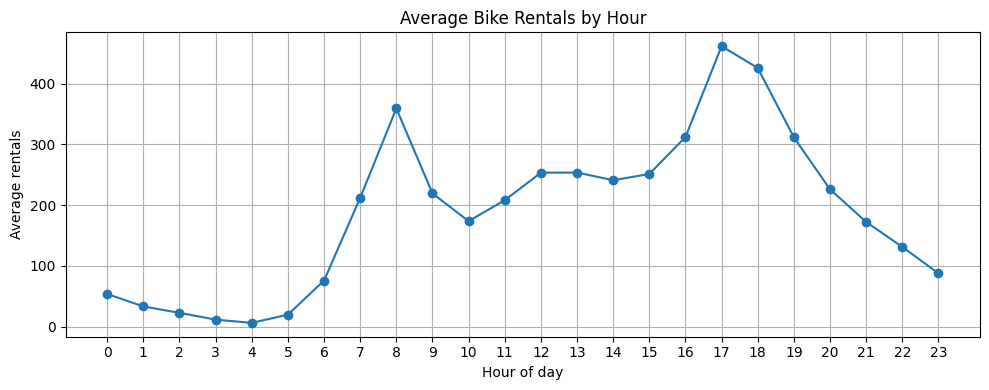

In [18]:
hourly_profile = data.groupby("hr")["cnt"].mean()

plt.figure(figsize=(10, 4))
plt.plot(hourly_profile.index, hourly_profile.values, marker="o")
plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of day")
plt.ylabel("Average rentals")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

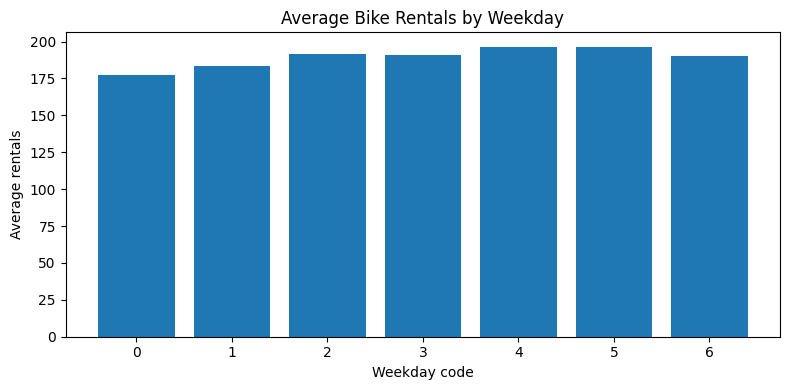

In [21]:
weekday_profile = data.groupby("weekday")["cnt"].mean()

plt.figure(figsize=(8, 4))
plt.bar(weekday_profile.index, weekday_profile.values)
plt.title("Average Bike Rentals by Weekday")
plt.xlabel("Weekday code")
plt.ylabel("Average rentals")
plt.tight_layout()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

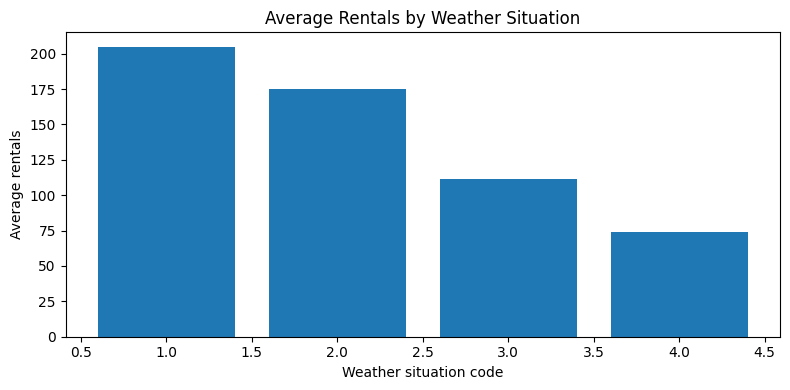

In [23]:
weather_profile = data.groupby("weathersit")["cnt"].mean()

plt.figure(figsize=(8, 4))
plt.bar(weather_profile.index, weather_profile.values)
plt.title("Average Rentals by Weather Situation")
plt.xlabel("Weather situation code")
plt.ylabel("Average rentals")
plt.tight_layout()
plt.show